# BridgeRNA biological prioritization and cross-study generalization

## Introduction

This benchmark evaluates disease-gene recovery and cross-study reproducibility of gene programs prioritized by frozen BridgeRNA, relative to differential expression (DE).

1. **Disease-gene recovery:** compare documented disease-gene overlap for Bridge top-500 modules and equally sized DE modules from the same samples in multiple sclerosis (MS), Crohn's disease, and systemic lupus erythematosus (SLE).
2. **Cross-study reproducibility:** compare recurrence across independent terrestrial studies and transfer to spaceflight/OSDR experiments for genes prioritized only by Bridge or only by DE in muscle atrophy, bone loss, and radiation injury.

Pharmacological mapping follows the biological reproducibility analyses and identifies candidate connections; it does not establish therapeutic efficacy.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

PACKAGE = Path.cwd()
if not (PACKAGE / 'data').exists():
    candidates = [Path.cwd() / 'benchmarks/drug_discovery', Path.cwd().parent / 'drug_discovery']
    PACKAGE = next((p.resolve() for p in candidates if (p / 'data').exists()), PACKAGE)
CACHE = PACKAGE / 'data'
FIGURES = PACKAGE / 'figures'
FIGURES.mkdir(exist_ok=True)

mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'figure.facecolor': 'white'
})
BRIDGE = '#2A6F97'
DE = '#D17A22'

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {mpl.__version__}')
print(f'Cached evidence: {CACHE}')

Python 3.11.0rc1 | pandas 2.3.3 | numpy 1.26.4 | matplotlib 3.10.9
Cached evidence: /home/walt/bridge-rna/benchmarks/drug_discovery/data


## Data and frozen protocol

Task 1 used one case-control cohort per disease. Task 2 used terrestrial discovery, terrestrial replication, and OSDR validation datasets for each space-relevant condition. Expression was aligned to Bridge's canonical 15,165-gene order and transformed as natural `log1p(TPM)`. The frozen `r7hnr92k` encoder and signed Integrated Gradients pipeline produced top-500 Bridge modules; matched DE used identical samples, contrasts, pairing/covariates, expressed-gene universes, and module sizes.

ARCHS4 exposure is an interpretation variable: several terrestrial replication cohorts were seen during pretraining, whereas the OSDR cohorts and most discovery cohorts were unseen. Results involving seen studies establish reproducibility but not strict out-of-pretraining generalization.

Frozen cohort definitions are recorded in the [disease cohort table](research_archive/deweerd_replication/results/locked_cohorts.csv), [space-condition dataset matrix](research_archive/drug_discovery/results/dataset_matrix.csv), and [space-condition sample manifest](research_archive/drug_discovery/results/manifests/sample_manifest.csv). Detailed scientific interpretation is retained in the [disease benchmark summary](research_archive/deweerd_replication/results/integrated_benchmark_summary.md), [space-condition benchmark summary](research_archive/drug_discovery/results/phase2_summary.md), and underlying condition-specific reports.

In [2]:
disease_cohorts = pd.read_csv(CACHE / 'locked_disease_cohorts.csv')
space_matrix = pd.read_csv(CACHE / 'dataset_matrix.csv')

display(disease_cohorts[[
    'disease_contrast', 'accession', 'tissue', 'case_samples', 'control_samples',
    'mapped_canonical_genes', 'archs4_train', 'archs4_validation', 'archs4_absent'
]].rename(columns={'disease_contrast': 'disease'}))
display(space_matrix)

assert len(disease_cohorts) == 3
assert len(space_matrix) == 9
assert set(space_matrix['condition']) == {'Radiation', 'Bone loss', 'Muscle atrophy'}

,disease,accession,tissue,case_samples,control_samples,mapped_canonical_genes,archs4_train,archs4_validation,archs4_absent
0,Multiple sclerosis — active lesion,GSE138614,brain white matter,16,25,15069,35,4,2
1,Crohn's disease — ileum,GSE101794,terminal ileum biopsy,61,13,10738,54,17,3
2,Systemic lupus erythematosus — blood,GSE72509,whole blood,99,18,13874,88,28,1


,condition,role,dataset,exact_primary_contrast,n_used,bridge_gene_coverage,pretraining_status,recommendation
0,Radiation,Terrestrial discovery,GSE297090,1 Gy gamma vs gamma mock and 1 Gy proton vs pr...,20 per modality,14954/15165 (98.6%),confirmed unseen,use
1,Radiation,Terrestrial replication,GSE184119,10 Gy vs 0 Gy within each of six cell types,24,12713/15165 (83.8%),confirmed seen,use; leakage-labeled
2,Radiation,OSDR validation,OSD-993 / GSE297560,each 4 Gy particle vs shipped particle control...,6 per modality,15096/15165 (99.5%),confirmed unseen,use; culture-replicate caveat
3,Bone loss,Terrestrial discovery,GSE189524,osteoporosis vs non-osteoporosis MSCs after su...,7 donors / 14 libraries,14665/15165 (96.7%),confirmed unseen,use; exploratory due to 3-vs-4 donor design an...
4,Bone loss,Terrestrial replication,GSE276529,GIOP cortical femur vs age-matched non-GIOP,9,15089/15165 (99.5%),confirmed unseen,use; etiology-qualified
5,Bone loss,OSDR validation,OSD-867 / GSE273868,ISS spaceflight vs ground control separately a...,6 per time stratum,15096/15165 (99.5%),confirmed unseen,use; bone-marrow MSC spaceflight proxy
6,Muscle atrophy,Terrestrial discovery,GSE211204,paired day-10 ULLS vs baseline,22 (11 pairs),14603/15165 (96.3%),confirmed partial exposure,use with leakage sensitivity
7,Muscle atrophy,Terrestrial replication,GSE113165,paired day-5 bed rest vs pre; age and sex stra...,56 (28 pairs),15076/15165 (99.4%),confirmed seen,select; leakage-labeled
8,Muscle atrophy,OSDR validation,OSD-684 / GSE234465,flight vs ground separately for young and old ...,6 per age stratum,15096/15165 (99.5%),confirmed unseen (unused split),use


## Methods and metrics

For Task 1, exact-CUI DisGeNET v7 overlap was tested with right-sided Fisher tests and BH correction. The all-association reference and top-500 module were prespecified as primary. Because the exact filtered reference sets used in the reference study were unavailable, this is a documented methodological analysis rather than an exact numerical replication.

For Task 2, each top-500 pair was partitioned into **Bridge-only**, **shared**, and **DE-only** genes. Primary descriptive metrics were recurrence in another independent same-condition dataset and terrestrial-to-OSDR Jaccard overlap. External condition-gene support, pathway coherence, mask-token deletion, and ChEMBL targetability were additional evidence layers. Overall partition differences do not have a saved paired null and are therefore reported as descriptive effect sizes. Radiation also had a prespecified matched-context analysis with paired tests and matched random gene sets.

Expanded ChEMBL 37 mapping included 4,389 clinical drugs, 2,046 human targets, and 16,986 drug-target edges, with a prespecified >10-target eligibility rule. Drug overlap can identify pharmacologically connected hypotheses but cannot establish beneficial direction or efficacy.

## Results: Task 1 — single-disease biological validation

### Disease-gene enrichment: BRIDGE versus differential expression

For each of the three existing disease cohorts, we compare its top-500 BRIDGE and matched DE sets with the same exact-CUI DisGeNET v7 all-association reference, restricted to that cohort's eligible gene universe. Bars show odds ratios from right-sided Fisher tests; the dashed line marks odds ratio 1 (no over-representation). All six lists are enriched after BH correction across the six primary tests. DE has higher observed enrichment in MS and Crohn's disease; BRIDGE has higher observed enrichment in SLE. These tests compare each list with background, not the significance of differences between methods.

This reproduces the **type of display** in de Weerd et al.'s Figure 3B, using our own saved reference definitions and results. Their `mmc2.xlsx` supplies contrast labels and summary counts, not the exact reference gene identities, so it does not establish a numerical replication of their 25 comparisons. No additional disease cohorts were analyzed.

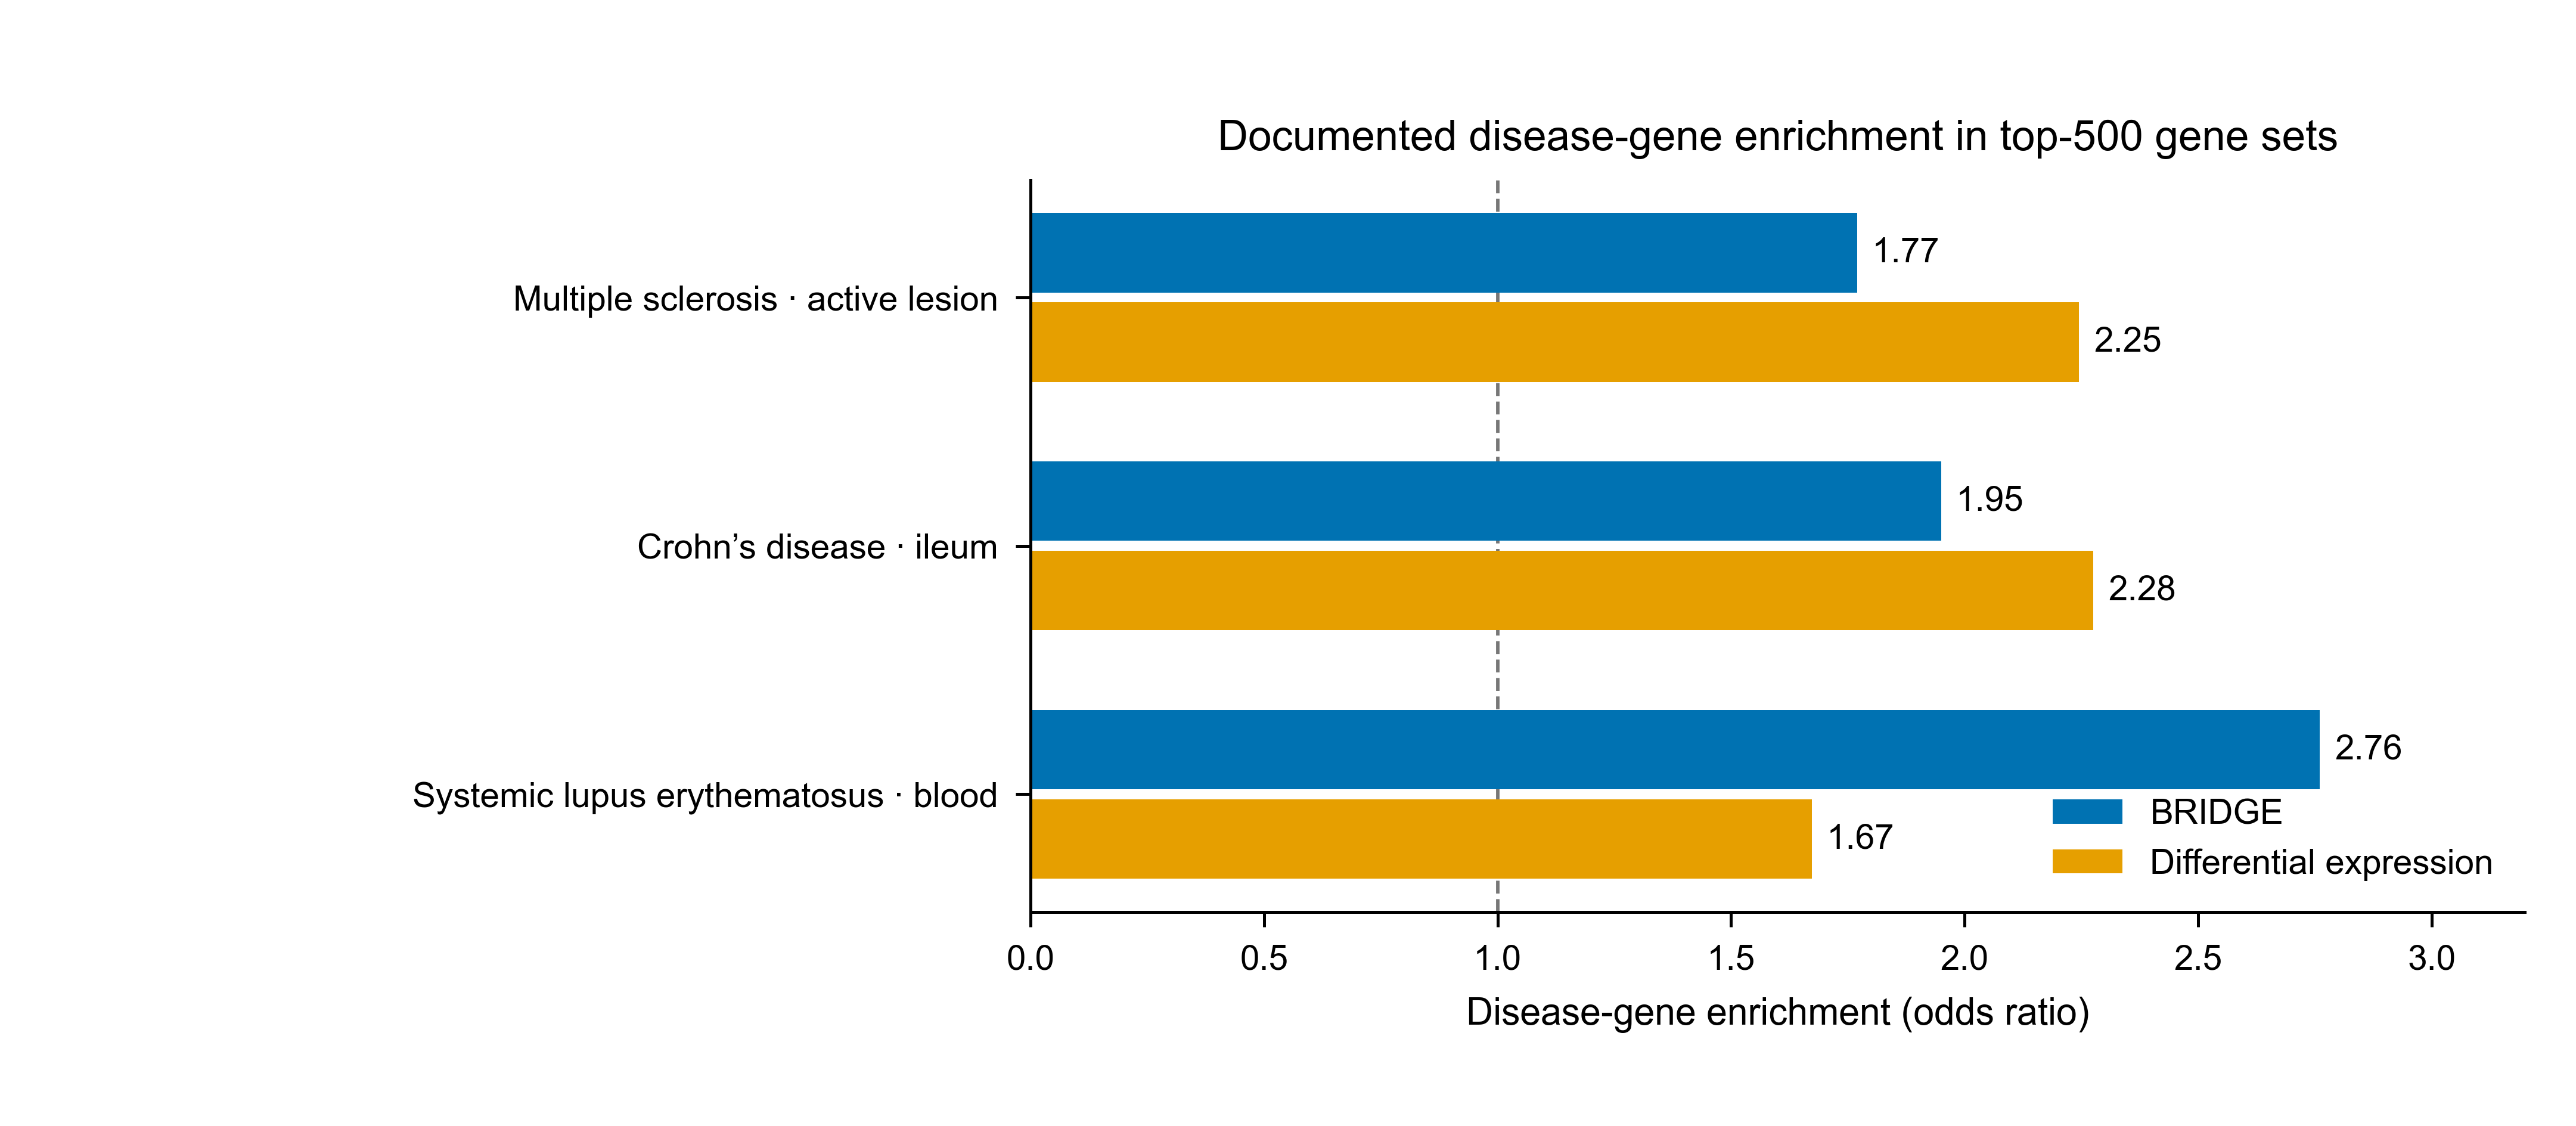

In [3]:
from IPython.display import Image
display(Image(filename=str(FIGURES / 'task1_disease_gene_enrichment.png')))

,disease_short,method,known_genes_recovered,odds_ratio,pvalue,fdr,universe_genes
58,Crohn's,Bridge,70,1.949568,2.217399e-06,3.326098e-06,10738
78,Crohn's,DE,79,2.275358,2.264883e-09,4.529765e-09,10738
18,MS,Bridge,72,1.769565,2.546801e-05,3.056161e-05,14991
38,MS,DE,87,2.245166,5.857263e-10,1.757179e-09,14991
98,SLE,Bridge,106,2.760400,2.362609e-16,1.417565e-15,13821
118,SLE,DE,72,1.673120,1.220965e-04,1.220965e-04,13821


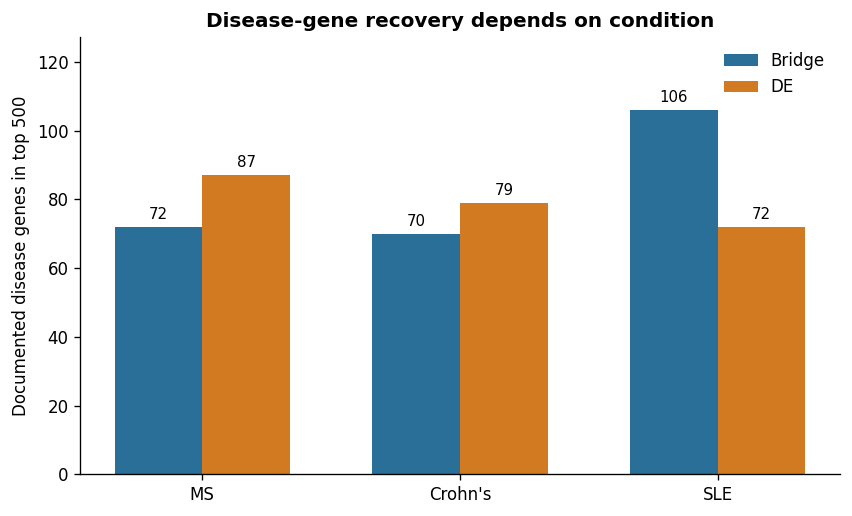

In [4]:
recovery = pd.read_csv(CACHE / 'disease_gene_recovery.csv')
primary = recovery.query("module_size == 500 and reference_definition == 'all_v7_associations'").copy()
primary['disease_short'] = primary['disease'].map({
    'Multiple sclerosis — active lesion': 'MS',
    "Crohn's disease — ileum": "Crohn's",
    'Systemic lupus erythematosus — blood': 'SLE',
})
primary = primary.sort_values(['disease_short', 'method'])
assert len(primary) == 6
assert (primary['fdr'] < 0.05).all()
display(primary[['disease_short', 'method', 'known_genes_recovered', 'odds_ratio', 'pvalue', 'fdr', 'universe_genes']])

order = ['MS', "Crohn's", 'SLE']
pivot = primary.pivot(index='disease_short', columns='method', values='known_genes_recovered').loc[order]
x = np.arange(len(order)); width = 0.34
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for offset, method, color in [(-width/2, 'Bridge', BRIDGE), (width/2, 'DE', DE)]:
    vals = pivot[method].to_numpy()
    bars = ax.bar(x + offset, vals, width, label=method, color=color)
    ax.bar_label(bars, padding=3, fontsize=9)
ax.set_xticks(x, order)
ax.set_ylabel('Documented disease genes in top 500')
ax.set_title('Disease-gene recovery depends on condition')
ax.legend(frameon=False)
ax.set_ylim(0, pivot.to_numpy().max() * 1.2)
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(FIGURES / f'task1_disease_gene_recovery.{ext}', bbox_inches='tight')
plt.show()

pivot.reset_index().to_csv(FIGURES / 'task1_disease_gene_recovery.csv', index=False)

All six top-500 modules were significantly enriched for documented disease genes. DE recovered more documented genes in MS (87 versus 72) and Crohn's disease (79 versus 70), whereas Bridge recovered more in SLE (106 versus 72). These observed differences were not tested as direct Bridge-versus-DE significance contrasts and therefore support disease-dependent complementarity, not a universal ordering.

## Results: Task 2 — cross-study and terrestrial-to-spaceflight generalization

,partition,recurrence_fraction,osdr_jaccard,targetable_fraction,significant_drugs,deletion_change,deletion_per100,fraction_remaining
0,Bridge-only,0.435307,0.158969,0.163337,3,0.063485,0.014344,0.825684
1,DE-only,0.117259,0.016042,0.146111,17,0.024569,0.005491,0.972798
2,Shared,0.122020,0.013071,0.161600,0,0.021649,0.032874,0.908335


,condition,partition,recurrence_fraction,osdr_jaccard,external_overlap,external_min_q,targetable_fraction
0,Bone loss,Bridge-only,0.423184,0.173361,148,0.000001,0.165698
1,Bone loss,DE-only,0.070701,0.016988,86,0.032159,0.131699
3,Muscle atrophy,Bridge-only,0.502570,0.174717,59,0.000052,0.160552
4,Muscle atrophy,DE-only,0.196575,0.019978,33,0.070768,0.168279
6,Radiation,Bridge-only,0.380166,0.128830,1,0.909784,0.163761
7,Radiation,DE-only,0.084501,0.011160,4,0.376260,0.138354


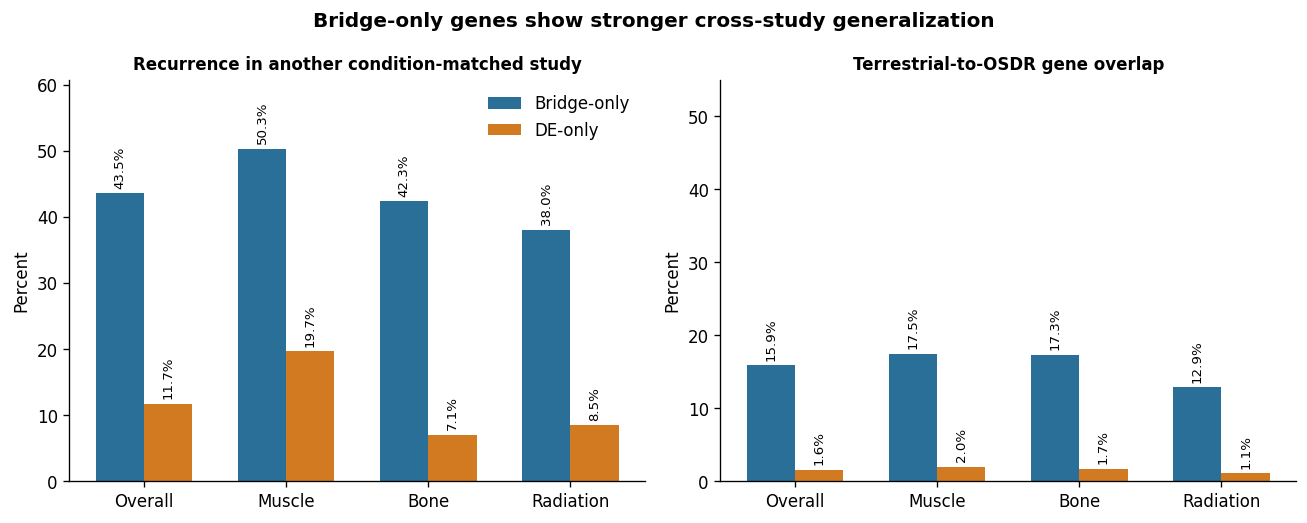

In [5]:
overall = pd.read_csv(CACHE / 'partition_overall_summary.csv')
condition = pd.read_csv(CACHE / 'partition_condition_summary.csv')
focus = condition[condition['partition'].isin(['Bridge-only', 'DE-only'])].copy()

display(overall)
display(focus[['condition', 'partition', 'recurrence_fraction', 'osdr_jaccard', 'external_overlap', 'external_min_q', 'targetable_fraction']])

assert np.isclose(overall.set_index('partition').loc['Bridge-only', 'recurrence_fraction'], 0.435307, atol=5e-7)
assert np.isclose(overall.set_index('partition').loc['DE-only', 'osdr_jaccard'], 0.016042, atol=5e-7)

conditions = ['Overall', 'Muscle atrophy', 'Bone loss', 'Radiation']
rows = []
for partition in ['Bridge-only', 'DE-only']:
    o = overall.set_index('partition').loc[partition]
    rows.append({'condition': 'Overall', 'partition': partition,
                 'recurrence_fraction': o['recurrence_fraction'], 'osdr_jaccard': o['osdr_jaccard']})
rows.extend(focus[['condition', 'partition', 'recurrence_fraction', 'osdr_jaccard']].to_dict('records'))
plot_df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True)
for ax, metric, title in [
    (axes[0], 'recurrence_fraction', 'Recurrence in another condition-matched study'),
    (axes[1], 'osdr_jaccard', 'Terrestrial-to-OSDR gene overlap'),
]:
    for offset, partition, color in [(-width/2, 'Bridge-only', BRIDGE), (width/2, 'DE-only', DE)]:
        vals = (plot_df[plot_df.partition == partition].set_index('condition').loc[conditions, metric] * 100).to_numpy()
        bars = ax.bar(np.arange(len(conditions)) + offset, vals, width, label=partition, color=color)
        ax.bar_label(bars, labels=[f'{v:.1f}%' for v in vals], padding=3, fontsize=8, rotation=90)
    ax.set_xticks(np.arange(len(conditions)), ['Overall', 'Muscle', 'Bone', 'Radiation'])
    ax.set_ylabel('Percent')
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, max(55, ax.get_ylim()[1] * 1.15))
axes[0].legend(frameon=False, loc='upper right')
fig.suptitle('Bridge-only genes show stronger cross-study generalization', fontweight='bold')
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(FIGURES / f'task2_cross_study_generalization.{ext}', bbox_inches='tight')
plt.show()
plot_df.to_csv(FIGURES / 'task2_cross_study_generalization.csv', index=False)

Across partitions, 43.53% of Bridge-only genes recurred in another same-condition dataset versus 11.73% of DE-only genes. Mean terrestrial-to-OSDR Jaccard was 0.15897 versus 0.01604. Muscle atrophy was the clearest individual condition (50.26% versus 19.66% recurrence; Jaccard 0.17472 versus 0.01998), and its Bridge-only module had significant external muscle-atrophy support (59 overlaps, q=5.24×10⁻⁵) whereas the DE-only partition did not pass FDR (33 overlaps, q=0.0708). Bone loss showed a similar transfer pattern and coherent extracellular-matrix/ossification biology. These aggregate partition comparisons are descriptive because a matched overall null was not saved.

### Representation deletion and targetability

In [6]:
deletion = pd.read_csv(CACHE / 'partition_deletion_summary.csv')
observed = deletion.query("panel_type == 'observed'")
del_summary = observed.groupby('partition', as_index=False).agg(
    mean_absolute_change=('absolute_score_change', 'mean'),
    sd_absolute_change=('absolute_score_change', 'std'),
    n=('absolute_score_change', 'size'),
    mean_per_100=('absolute_change_per_100_genes', 'mean'),
)
display(del_summary)
display(overall[['partition', 'targetable_fraction', 'deletion_change', 'deletion_per100']])

,partition,mean_absolute_change,sd_absolute_change,n,mean_per_100
0,Bridge-only,0.068450,0.046423,9,0.016062
1,DE-only,0.017391,0.030041,9,0.003931
2,Shared,0.029801,0.026064,9,0.034412


,partition,targetable_fraction,deletion_change,deletion_per100
0,Bridge-only,0.163337,0.063485,0.014344
1,DE-only,0.146111,0.024569,0.005491
2,Shared,0.161600,0.021649,0.032874


Masking Bridge-only genes altered the frozen Bridge axis more than masking DE-only genes in the saved descriptive deletion analysis (overall absolute change 0.0635 versus 0.0246; per 100 genes 0.0143 versus 0.00549). Targetable fractions were similar (16.33% versus 14.61%), so greater Bridge-only recurrence is not explained by substantially greater representation in ChEMBL. Deletion is a representation diagnostic, not a causal intervention.

## Radiation requires context matching

,context_distance,pairs,mean_bridge_jaccard,mean_de_jaccard,mean_bridge_minus_de,bridge_higher_pairs,wilcoxon_statistic,wilcoxon_pvalue
0,all,21,0.236340,0.131152,0.105187,18,7.0,0.000018
1,1,7,0.423376,0.349483,0.073893,4,6.0,0.218750
2,3,4,0.144296,0.026546,0.117751,4,0.0,0.125000
3,4,10,0.142232,0.020164,0.122068,10,0.0,0.001953


,cross_study_core,all_seven_modules
method,,
Bridge,237,15
DE,35,0


,osdr_modality,method,overlap_count,jaccard,matched_random_empirical_p
0,gamma,Bridge,165,0.197605,0.000500
1,gamma,DE,22,0.022495,0.406297
2,proton,Bridge,169,0.203369,0.000500
3,proton,DE,17,0.017294,0.784108
4,iron,Bridge,172,0.207729,0.000500
5,iron,DE,17,0.017294,0.772614
6,silicon,Bridge,157,0.186240,0.000500
7,silicon,DE,19,0.019368,0.596202


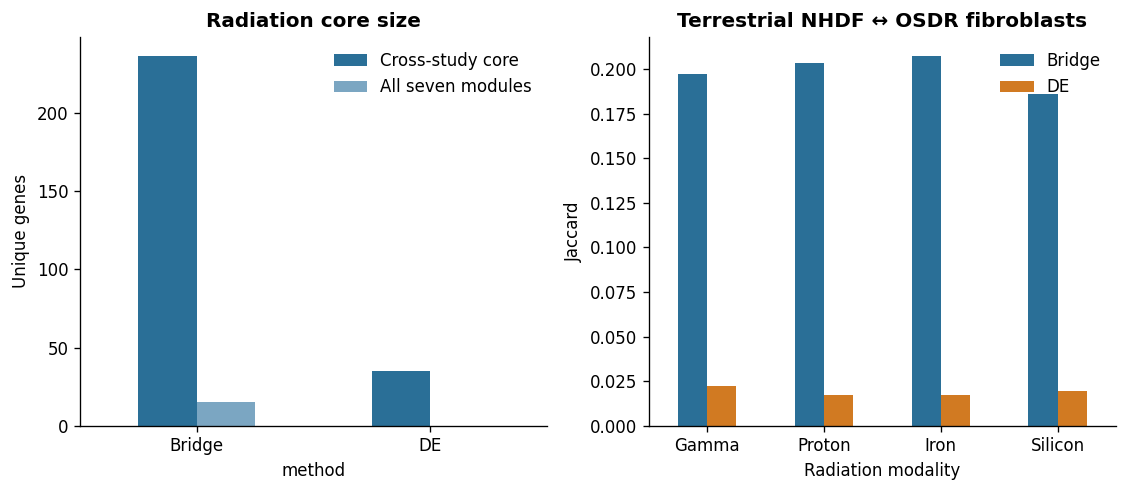

In [7]:
stability = pd.read_csv(CACHE / 'radiation_stability.csv')
core = pd.read_csv(CACHE / 'radiation_core_genes.csv')
fibro = pd.read_csv(CACHE / 'fibroblast_comparison.csv')

all_pairs = stability.query("context_distance == 'all'").iloc[0]
core_counts = (core.assign(core=lambda d: d['classification'].eq('majority_cross_study_core') |
                                           d['classification'].eq('strict_universal'))
                 .query('core').groupby('method')['gene'].nunique())
strict_counts = core.query("classification == 'strict_universal'").groupby('method')['gene'].nunique()
core_table = pd.DataFrame({
    'cross_study_core': core_counts.reindex(['Bridge', 'DE'], fill_value=0),
    'all_seven_modules': strict_counts.reindex(['Bridge', 'DE'], fill_value=0),
})
display(stability)
display(core_table)
display(fibro[['osdr_modality', 'method', 'overlap_count', 'jaccard', 'matched_random_empirical_p']])

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
core_table.plot.bar(ax=axes[0], color=[BRIDGE, '#7BA6C2'], rot=0)
axes[0].set_ylabel('Unique genes')
axes[0].set_title('Radiation core size')
axes[0].legend(['Cross-study core', 'All seven modules'], frameon=False)
fib_pivot = fibro.pivot(index='osdr_modality', columns='method', values='jaccard').loc[['gamma','proton','iron','silicon']]
fib_pivot.plot.bar(ax=axes[1], color=[BRIDGE, DE], rot=0)
axes[1].set_xticklabels(['Gamma', 'Proton', 'Iron', 'Silicon'])
axes[1].set_ylabel('Jaccard')
axes[1].set_xlabel('Radiation modality')
axes[1].set_title('Terrestrial NHDF ↔ OSDR fibroblasts')
axes[1].legend(frameon=False)
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(FIGURES / f'radiation_context_results.{ext}', bbox_inches='tight')
plt.show()
core_table.reset_index(names='method').to_csv(FIGURES / 'radiation_core_counts.csv', index=False)
fib_pivot.reset_index().to_csv(FIGURES / 'radiation_fibroblast_jaccard.csv', index=False)

Bridge exceeded DE in 18 of 21 matched radiation comparisons; the mean paired Bridge-minus-DE Jaccard difference was +0.1052 (Wilcoxon p=1.83×10⁻⁵). The Bridge cross-study core contained 237 genes versus 35 for DE; 15 Bridge genes and no DE genes occurred in all seven modules. In the biologically matched NHDF-to-OSDR-fibroblast analysis, Bridge Jaccard was 0.186–0.208 with matched-random empirical p=0.0005 for every modality, versus 0.017–0.022 for DE. Radiation therefore supports stable prioritization after context matching, but not necessarily stable signed response across every tissue and exposure.

## Pharmacologically connected hypotheses

In [8]:
drug_sensitivity = pd.read_csv(CACHE / 'expanded_vs_restrictive.csv')
targets = pd.read_csv(CACHE / 'muscle_target_summary.csv')
removal = pd.read_csv(CACHE / 'muscle_target_removal.csv')
display(drug_sensitivity)
display(targets.head(7))
display(removal)

,condition,bridge_mean_pairwise_top25_jaccard_expanded,de_mean_pairwise_top25_jaccard_expanded,bridge_minus_de_expanded,exact_p_expanded,permutations_expanded,bridge_mean_pairwise_top25_jaccard_restrictive,de_mean_pairwise_top25_jaccard_restrictive,bridge_minus_de_restrictive,exact_p_restrictive,permutations_restrictive,delta_bridge_mean_pairwise_top25_jaccard,delta_de_mean_pairwise_top25_jaccard,delta_bridge_minus_de
0,Radiation,0.064151,0.073534,-0.009383,0.75,8,0.155354,0.041667,0.113688,0.25,8,-0.091203,0.031867,-0.123071
1,Bone loss,0.097138,0.035165,0.061972,0.25,8,0.142308,0.180556,-0.038248,0.75,8,-0.045170,-0.145390,0.100220
2,Muscle atrophy,0.164080,0.006803,0.157277,0.25,8,0.714286,0.182299,0.531987,0.25,8,-0.550206,-0.175496,-0.374709


,target_gene,drug_count,drugs,dataset_count,datasets,drug_dataset_supports
0,ERBB2,3,AFATINIB;DACOMITINIB ANHYDROUS;NERATINIB,3,GSE113165;GSE211204;GSE234465,9
1,PDE5A,1,IBUDILAST,3,GSE113165;GSE211204;GSE234465,3
2,ADRB2,1,SOTALOL,1,GSE234465,1
3,CPT1B,1,PERHEXILINE,1,GSE211204,1
4,CPT2,1,PERHEXILINE,1,GSE113165,1
5,PDE10A,1,IBUDILAST,1,GSE234465,1
6,SCN5A,1,VERNAKALANT,1,GSE234465,1


,removal_type,removed,mean_jaccard,absolute_change,fraction_of_baseline_lost
0,drug,IBUDILAST,0.666667,-0.047619,0.066667
1,none,none,0.714286,0.000000,0.000000
2,target,ERBB2,0.500000,-0.214286,0.300000
3,target,PDE5A,0.619048,-0.095238,0.133333
4,target,CPT1B,0.679365,-0.034921,0.048889
5,target,CPT2,0.679365,-0.034921,0.048889
6,target,PDE10A,0.714286,0.000000,0.000000
7,target,ADRB2,0.777778,0.063492,-0.088889
8,target,SCN5A,0.777778,0.063492,-0.088889


In muscle, recurrent target mapping connected ERBB2 to afatinib, dacomitinib, and neratinib, and PDE5A/PDE10A to ibudilast. These are candidates for condition-relevant experiments, not established treatments. The restrictive drug graph produced Bridge versus DE convergence Jaccard of 0.714 versus 0.182, but expanded ChEMBL produced 0.164 versus 0.0068. Removing ERBB2 lowered the restrictive Bridge estimate to 0.500, and removing PDE5A lowered it to 0.619; individual recurrent drug enrichments did not pass FDR. The target universe and connected hub genes therefore materially affect compound-level convergence even when the qualitative Bridge-greater-than-DE ordering remains.

## Negative results and scope boundary

Bridge did not uniformly exceed DE. DE had stronger documented disease-gene recovery in MS and Crohn's disease, while Bridge was stronger in SLE. The expanded-ChEMBL muscle effect was much smaller than the restrictive estimate, and the exact method-label permutation test was not significant. No drug candidate is validated by this benchmark.

Exploratory generic perturbation checks using LINCS/L1000 and GSE264130 were conducted elsewhere in the research record, but their assay and cell contexts were not sufficiently matched to the six conditions for condition-specific biological inference. They are excluded from this notebook's evidence base and do not alter the frozen biological-prioritization results.

## Limitations

- Only three independent studies were available per space-relevant condition, and tissues, exposures, and model systems were heterogeneous.
- Some terrestrial cohorts were represented in ARCHS4 pretraining. GSE184119 and GSE113165 are reproducibility cohorts, not strict held-out generalization tests; GSE211204 had partial exposure. The OSDR cohorts were held out.
- Exact DisGeNET reference filtering from the motivating study and an authorized DrugBank export were unavailable; documented DisGeNET v7 and ChEMBL 37 universes were used instead.
- Overall Bridge-only versus DE-only recurrence differences are descriptive and lack a saved paired null. Condition-specific external enrichment and radiation matched-random tests provide stronger inferential support.
- ChEMBL connectivity is influenced by target annotation density and hub genes and does not determine beneficial direction, dose, safety, or efficacy.
- Radiation prioritization is context dependent; recurrence of rank does not imply consistent direction in every tissue or radiation modality.

## Conclusion

Bridge recovered recognizable disease biology and, most importantly, identified complementary gene programs that transferred across independent terrestrial and spaceflight studies more strongly than genes prioritized only by conventional DE. Evidence was strongest for muscle atrophy and bone loss and became clear for radiation when biological context was matched. Portions of these reproducible programs map to pharmacologically actionable targets, but the drug lists are resource- and hub-sensitive hypotheses. The benchmark supports Bridge as a complement to DE for discovering reproducible space-biology programs; it does not establish robust therapeutic countermeasures.

In [10]:
# Final integrity checks for the displayed evidence.
assert set(primary['known_genes_recovered']) == {72, 87, 70, 79, 106}
assert int(all_pairs['bridge_higher_pairs']) == 18 and int(all_pairs['pairs']) == 21
assert core_table.loc['Bridge', 'cross_study_core'] == 237
assert core_table.loc['DE', 'cross_study_core'] == 35
assert core_table.loc['Bridge', 'all_seven_modules'] == 15
assert core_table.loc['DE', 'all_seven_modules'] == 0
assert np.allclose(fibro.query("method == 'Bridge'")['matched_random_empirical_p'], 1 / 2001, atol=1e-9)
print('All notebook evidence checks passed.')

All notebook evidence checks passed.
